# AH2179 Traffic project — A4: Fixes for congestion

A2/A3 showed where the model fails: in congestion (error ≈ 2× free flow), at **onsets** (free → congested within 15 min), at sudden
drops, and through a slowly drifting daily/seasonal level. This notebook tests four fixes that only use data available in real time:

| Fix | Idea | New features / method |
|---|---|---|
| **F1 congestion state** | *Where are we in the congestion cycle?* How long has the portal been congested, how many portals are congested (queue extent), is speed falling? | `r_p*_run`, `r_p*_today`, `v_p*_d15`, `corr_n_cong`, `corr_vmin` |
| **F2 1-min nowcast** | 5-min averages hide a breakdown that starts inside the bin. The 1-min data show it up to 4 min earlier. | last-minute speed/flow, min speed in last 5 min, 5-min speed slope, 15-min speed std (stop-and-go) |
| **F3 day anomaly** | Is today busier/quieter than the historical profile? (residual autocorrelation over hours in A3) | flow minus profile, mean over last 60 / 180 min |
| **F4 online bias correction** | Subtract the model's own recent error (known 15 min late) — fights the monthly drift found in A3 | post-processing, tuned on validation |
| (F5) Δ-target | Predict the *change* q(t+15) − q(t) instead of the level | target transformation |

**Protocol.** Each fix is added to the A2 feature set (`base`) and trained with the A2 hyper-parameters; tree counts by early
stopping on validation; the choice is made on **validation**; the chosen model is refitted on all 2021 data and scored on the ALL-day
**evaluation** file, with the day-level tests from A3. **The final hold-out is not used**: it was already used once for the A2 model,
and a model developed after looking at results is no longer "unseen-data" evidence — see the last section.

In [1]:
import warnings, time; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from scipy import stats
import xgboost as xgb
import traffic_prep as tp
tp.set_window(0, 24 * 60)

TARGET_P = "p55620"; TARGET = f"q_{TARGET_P}"; Y = f"y_{TARGET}"
REFIT = False                # True = recompute everything (ignore the cache)
RUN_FINAL_A4 = False         # see the last section before changing this
SEED, RES_MIN, H = 42, 5, 3
VAL_START = "2021-11-15"

DATA = Path("../dataset_for_traffic_project_assignment_ALLday")
IN = Path("../processed_allday"); MOD = Path("../models_allday"); RES = Path("../results_allday"); FIG = Path("../figures_allday")
CACHE = MOD / "cache_A4"; CACHE.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
def save(fig, name): fig.savefig(FIG / f"A4_{name}.png", bbox_inches="tight", dpi=150)
def cached(name, fn):
    f = CACHE / f"{name}.joblib"
    if f.exists() and not REFIT: return joblib.load(f)
    t0 = time.time(); obj = fn(); joblib.dump(obj, f); print(f"[{name}] computed in {time.time() - t0:.0f} s"); return obj

prep = joblib.load(MOD / f"prep_{TARGET}.joblib")          # from A2
BEST, X_BASE = prep["xgb_params"], prep["x_cols"]
reg = joblib.load(IN / "regime_model.joblib")
PROFILE = {"stage1": pd.read_pickle(IN / "hist_profile_train_split.pkl"),   # train split only -> train/val rows
           "stage2": pd.read_pickle(IN / "hist_profile_training.pkl")}      # all 2021 -> full refit and 2022 rows
PROFILE_OF = {"train": "stage1", "val": "stage1", "full": "stage2", "evaluation": "stage2", "final_evaluation": "stage2"}
lane_stats = tp.LaneStats.from_json(IN / "lane_stats.json")
SPLITS = ["train", "val", "full", "evaluation", "final_evaluation"]     # full = all 2021, for the final refit
FILE_OF = {"train": "training", "val": "training", "full": "training", "evaluation": "evaluation", "final_evaluation": "final_evaluation"}
F = {n: pd.read_pickle(IN / f"features_{n}.pkl") for n in SPLITS}
print({n: d.shape for n, d in F.items()})

{'train': (48093, 174), 'val': (13537, 174), 'full': (61632, 174), 'evaluation': (23040, 174), 'final_evaluation': (29088, 174)}


## 1. Build the new features

In [2]:
def wide_1min(file):
    raw = tp.load_raw(DATA / f"{file}_dataset.csv")
    lg, _ = tp.clean_lane_data(raw, lane_stats, causal=True)           # real-time cleaning: inputs never see the future
    return tp.to_wide(tp.aggregate_portal(lg, lane_stats, res="1min"))

def new_features(file):
    Ff = pd.concat([F[n] for n in SPLITS if FILE_OF[n] == file]); Ff = Ff[~Ff.index.duplicated()].sort_index()
    idx = Ff.index
    # 5-min portal series (causal, gap-filled, as used for features) = the lag-0 columns of the feature table
    w5 = pd.DataFrame({f"{a}_{tp.PORTAL_COL[k]}": Ff[f"{a}_{tp.PORTAL_COL[k]}_lag0"] for a in ("q", "v") for k in tp.PORTALS_DOWNSTREAM})
    w1 = wide_1min(file)
    # day anomaly against both profiles; each split picks its own below (train/val: train-split profile)
    return pd.concat([tp.nowcast_features(w1, idx), tp.congestion_state_features(w5, reg, idx)]
                     + [tp.anomaly_features(w5, p, idx).add_suffix(f"@{s}") for s, p in PROFILE.items()], axis=1)

NEW = {f: cached(f"newfeat_{f}", lambda f=f: new_features(f)) for f in ["training", "evaluation", "final_evaluation"]}
for n in SPLITS:
    nf, st = NEW[FILE_OF[n]], f"@{PROFILE_OF[n]}"
    nf = nf[[c for c in nf.columns if "@" not in c or c.endswith(st)]].rename(columns=lambda c: c.replace(st, ""))
    F[n] = tp.corridor_features(F[n].join(nf))

new_cols = [c for c in F["train"].columns if c not in X_BASE and not c.startswith("y_")]
G_STATE = [c for c in new_cols if c.endswith(("_run", "_today")) or (c.startswith("v_p") and c.endswith("_d15"))] + ["corr_n_cong", "corr_vmin"]
G_NOW = [c for c in new_cols if "_1m" in c] + ["corr_v1m_drop"]
G_ANOM = [c for c in new_cols if "_anom" in c]
print(f"F1 state: {len(G_STATE)} | F2 1-min: {len(G_NOW)} | F3 anomaly: {len(G_ANOM)} new features")

# sanity: at a congestion onset the 1-min minimum speed is lower than the 5-min mean -> earlier warning
tr = F["train"]; ons = (tr[f"r_{TARGET_P}_lag0"] < .5) & (tr[f"y_reg_{TARGET}"] == 1)
pd.DataFrame({"5-min mean speed at t": tr.loc[ons, f"v_{TARGET_P}_lag0"].describe(),
              "lowest 1-min speed in last 5 min": tr.loc[ons, f"v_{TARGET_P}_1mmin5"].describe()}).T.round(1)

F1 state: 26 | F2 1-min: 41 | F3 anomaly: 17 new features


,count,mean,std,min,25%,50%,75%,max
5-min mean speed at t,602.0,63.2,5.0,52.5,60.0,63.5,66.8,80.5
lowest 1-min speed in last 5 min,600.0,58.2,8.3,20.2,54.4,59.9,64.0,74.8


## 2. Helpers: subsets, metrics, day-level tests

In [3]:
def subsets(d):
    ok = d[Y].notna(); tod = d["tod_target_min"]; rt = d[f"r_{TARGET_P}_lag0"]; ry = d[f"y_reg_{TARGET}"]
    return {"all day": ok, "07:30–08:30": ok & tod.between(450, 510), "15:00–18:00": ok & tod.between(900, 1080),
            "free flow at t+15": ok & (ry == 0), "congested at t+15": ok & (ry == 1),
            "onset (free→cong)": ok & (rt < .5) & (ry == 1), "recovery (cong→free)": ok & (rt >= .5) & (ry == 0)}

def rmse_table(preds, split):
    d = F[split]; y = d[Y]; S = subsets(d)
    t = pd.DataFrame({s: {k: np.sqrt(((p[m] - y[m]) ** 2).mean()) for k, p in preds.items()} for s, m in S.items()}).T
    t.insert(0, "n", [int(m.sum()) for m in S.values()]); return t.round(0)

def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(o): run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj

def day_test(pa, pb, split, sub):
    '''paired t-test on daily MSE differences (A − B) + ΔRMSE with day-bootstrap 95% CI'''
    d = F[split]; m = subsets(d)[sub]; y = d[Y][m]
    day = (d.index[m] - pd.Timedelta(minutes=RES_MIN)).normalize()
    L = pd.DataFrame({"a": (pa[m] - y) ** 2, "b": (pb[m] - y) ** 2}).groupby(day)
    S, n = L.sum().to_numpy(), L.size().to_numpy(); dd = (S[:, 0] - S[:, 1]) / n
    t = stats.ttest_1samp(dd, 0)
    idx = np.random.default_rng(SEED).integers(0, len(n), (2000, len(n)))
    r = np.sqrt(S[idx].sum(1) / n[idx].sum(1)[:, None]); lo, hi = np.percentile(r[:, 0] - r[:, 1], [2.5, 97.5])
    ra, rb = np.sqrt(S[:, 0].sum() / n.sum()), np.sqrt(S[:, 1].sum() / n.sum())
    return {"ΔRMSE": ra - rb, "95% CI": f"[{lo:.1f}, {hi:.1f}]", "days": len(n), "p": t.pvalue}

base_params = dict(n_estimators=4000, learning_rate=0.05, tree_method="hist", max_bin=128, objective="reg:squarederror",
                   early_stopping_rounds=50, n_jobs=4, random_state=SEED, eval_metric="rmse")
tr, va = F["train"][F["train"][Y].notna()], F["val"][F["val"][Y].notna()]
level = lambda d: d[f"{TARGET}_lag0"].fillna(d[f"hist_{TARGET}"])      # current flow (for the Δ-target)

## 3. Ablation on validation
Every variant: XGBoost with the A2 hyper-parameters, trained on train (2021-06-01 – 11-14), tree count by early stopping on validation.

In [4]:
VARIANTS = {"base (A2 features)": X_BASE,
            "+ F1 congestion state": X_BASE + G_STATE,
            "+ F2 1-min nowcast": X_BASE + G_NOW,
            "+ F3 day anomaly": X_BASE + G_ANOM,
            "all new (F1+F2+F3)": X_BASE + G_STATE + G_NOW + G_ANOM}

def fit_variant(cols, delta=False):
    yt = tr[Y] - level(tr) if delta else tr[Y]; yv = va[Y] - level(va) if delta else va[Y]
    m = xgb.XGBRegressor(**base_params, **BEST); m.fit(tr[cols], yt, eval_set=[(va[cols], yv)], verbose=False)
    return m

FIT = {name: cached(f"train_{i}", lambda c=cols: fit_variant(c)) for i, (name, cols) in enumerate(VARIANTS.items())}
ALLCOLS = VARIANTS["all new (F1+F2+F3)"]
FIT["all new + Δ-target (F5)"] = cached("train_delta", lambda: fit_variant(ALLCOLS, delta=True))
COLS = {**VARIANTS, "all new + Δ-target (F5)": ALLCOLS}
DELTA = {k: k.endswith("(F5)") for k in COLS}

def predict(m, cols, d, delta, n=None):
    p = m.predict(d[cols], iteration_range=(0, n) if n else None)
    return pd.Series(p + (level(d).to_numpy() if delta else 0), index=d.index)

val_pred = {k: predict(m, COLS[k], F["val"], DELTA[k], m.best_iteration + 1) for k, m in FIT.items()}
TREES = {k: m.best_iteration + 1 for k, m in FIT.items()}
val_tab = rmse_table(val_pred, "val"); val_tab.to_csv(RES / f"A4_val_rmse_{TARGET}.csv")
print("trees:", TREES); val_tab

trees: {'base (A2 features)': 287, '+ F1 congestion state': 146, '+ F2 1-min nowcast': 414, '+ F3 day anomaly': 108, 'all new (F1+F2+F3)': 240, 'all new + Δ-target (F5)': 455}


,n,base (A2 features),+ F1 congestion state,+ F2 1-min nowcast,+ F3 day anomaly,all new (F1+F2+F3),all new + Δ-target (F5)
all day,13418,284.0,285.0,280.0,279.0,276.0,279.0
07:30–08:30,611,272.0,271.0,279.0,268.0,262.0,258.0
15:00–18:00,1738,458.0,459.0,451.0,453.0,446.0,459.0
free flow at t+15,11992,243.0,245.0,240.0,239.0,236.0,235.0
congested at t+15,1426,512.0,511.0,501.0,501.0,498.0,519.0
onset (free→cong),156,597.0,587.0,571.0,603.0,567.0,601.0
recovery (cong→free),168,617.0,617.0,617.0,592.0,583.0,577.0


### F4: online bias correction — tuned on validation
ŷ′(t) = ŷ(t) − w · EWMA(errors known at t). The error of a forecast made at s is only known at s + 15 min, so only forecasts made
up to t − 15 min are used. Half-life (in 5-min steps) and weight w are chosen on validation.

In [5]:
BEST_VAR = val_tab.loc["all day"].drop("n").idxmin()
print("best feature variant on validation:", BEST_VAR)
pv = val_pred[BEST_VAR]; yv_all = F["val"][Y]
grid_bc = {(h, w): np.sqrt(((tp.online_bias_correction(pv, yv_all, H, h, w) - yv_all) ** 2).mean())
           for h in [2, 4, 8, 16, 32, 64] for w in [0.25, 0.5, 1.0]}
bc = pd.Series(grid_bc).unstack().round(1); bc.index.name = "half-life (steps)"; bc.columns.name = "weight"
HL, WB = min(grid_bc, key=grid_bc.get)
no_bc = np.sqrt(((pv - yv_all) ** 2).mean())
print(f"validation RMSE without correction {no_bc:.1f}; best correction half-life {HL} steps ({HL * RES_MIN} min), weight {WB}: {grid_bc[(HL, WB)]:.1f}")
val_pred[f"{BEST_VAR} + F4 bias corr."] = tp.online_bias_correction(pv, yv_all, H, HL, WB)
bc

best feature variant on validation: all new (F1+F2+F3)
validation RMSE without correction 276.1; best correction half-life 64 steps (320 min), weight 1.0: 272.8


weight,0.25,0.50,1.00
half-life (steps),,,
2,276.8,283.0,310.7
4,275.0,277.5,292.5
8,274.1,274.3,281.4
16,273.9,273.2,276.2
32,274.0,273.0,273.9
64,274.1,272.9,272.8


## 4. Refit on all 2021 data → ALL-day evaluation file

In [6]:
full = F["full"]; full = full[full[Y].notna()]     # all 2021, out-of-fold hist input (A1)
def refit(cols, n, delta):
    m = xgb.XGBRegressor(**{**base_params, "early_stopping_rounds": None, "n_estimators": int(n * 1.15)}, **BEST)
    return m.fit(full[cols], full[Y] - level(full) if delta else full[Y], verbose=False)
REF = {k: cached(f"refit_{i}", lambda k=k: refit(COLS[k], TREES[k], DELTA[k])) for i, k in enumerate(COLS)}

ev = F["evaluation"]
pred = {k: predict(m, COLS[k], ev, DELTA[k]) for k, m in REF.items()}
pred[f"{BEST_VAR} + F4 bias corr."] = tp.online_bias_correction(pred[BEST_VAR], ev[Y], H, HL, WB)
a2 = pd.read_pickle(RES / f"predictions_evaluation_{TARGET}.pkl")      # saved by A3 (A2 models)
pred["A2 selected (xgb single + aug)"] = a2["xgb single + aug"].reindex(ev.index)
pred["persistence"] = level(ev)
ev_tab = rmse_table(pred, "evaluation"); ev_tab.to_csv(RES / f"A4_evaluation_rmse_{TARGET}.csv")
print("check: 'base (A2 features)' should reproduce A2 'xgb single' (evaluation_rmse file of A2)")
ev_tab

check: 'base (A2 features)' should reproduce A2 'xgb single' (evaluation_rmse file of A2)


,n,base (A2 features),+ F1 congestion state,+ F2 1-min nowcast,+ F3 day anomaly,all new (F1+F2+F3),all new + Δ-target (F5),all new (F1+F2+F3) + F4 bias corr.,A2 selected (xgb single + aug),persistence
all day,21824,306.0,304.0,306.0,302.0,303.0,300.0,300.0,300.0,403.0
07:30–08:30,1040,285.0,288.0,278.0,274.0,276.0,275.0,280.0,268.0,411.0
15:00–18:00,2958,464.0,462.0,469.0,465.0,463.0,467.0,461.0,464.0,559.0
free flow at t+15,19646,265.0,265.0,263.0,262.0,261.0,259.0,259.0,259.0,370.0
congested at t+15,2177,554.0,544.0,559.0,542.0,550.0,544.0,543.0,544.0,623.0
onset (free→cong),297,672.0,671.0,670.0,669.0,681.0,640.0,677.0,663.0,749.0
recovery (cong→free),289,595.0,576.0,575.0,568.0,578.0,607.0,581.0,552.0,1045.0


In [7]:
# day-level paired tests of every fix against the base model (two-sided, Holm over the whole table)
rows = []
for k in [c for c in pred if c not in ("base (A2 features)", "persistence", "A2 selected (xgb single + aug)")]:
    for s in ["all day", "07:30–08:30", "congested at t+15", "onset (free→cong)", "recovery (cong→free)"]:
        rows.append({"variant": k, "subset": s, **day_test(pred[k], pred["base (A2 features)"], "evaluation", s)})
TESTS = pd.DataFrame(rows); TESTS["p (Holm)"] = holm(TESTS["p"])
TESTS["significant"] = np.where(TESTS["p (Holm)"] < .05, "yes", "no")
TESTS.to_csv(RES / f"A4_tests_vs_base_{TARGET}.csv", index=False)
piv = TESTS.pivot(index="variant", columns="subset", values="ΔRMSE").round(1)
sig = TESTS.pivot(index="variant", columns="subset", values="p (Holm)")
piv.astype(str) + np.where(sig < .05, " *", "")        # ΔRMSE vs base (veh/h, negative = better); * = significant after Holm

subset,07:30–08:30,all day,congested at t+15,onset (free→cong),recovery (cong→free)
variant,,,,,
+ F1 congestion state,3.2,-2.2,-10.5,-0.3,-19.1
+ F2 1-min nowcast,-6.3,-0.8,4.4,-1.2,-20.1
+ F3 day anomaly,-10.6,-4.5 *,-12.0 *,-2.9,-27.3
all new (F1+F2+F3),-9.0,-3.6,-4.1,9.0,-17.3
all new (F1+F2+F3) + F4 bias corr.,-4.7,-6.3,-10.9,5.7,-14.7
all new + Δ-target (F5),-9.8,-6.6,-10.1,-31.2,11.7


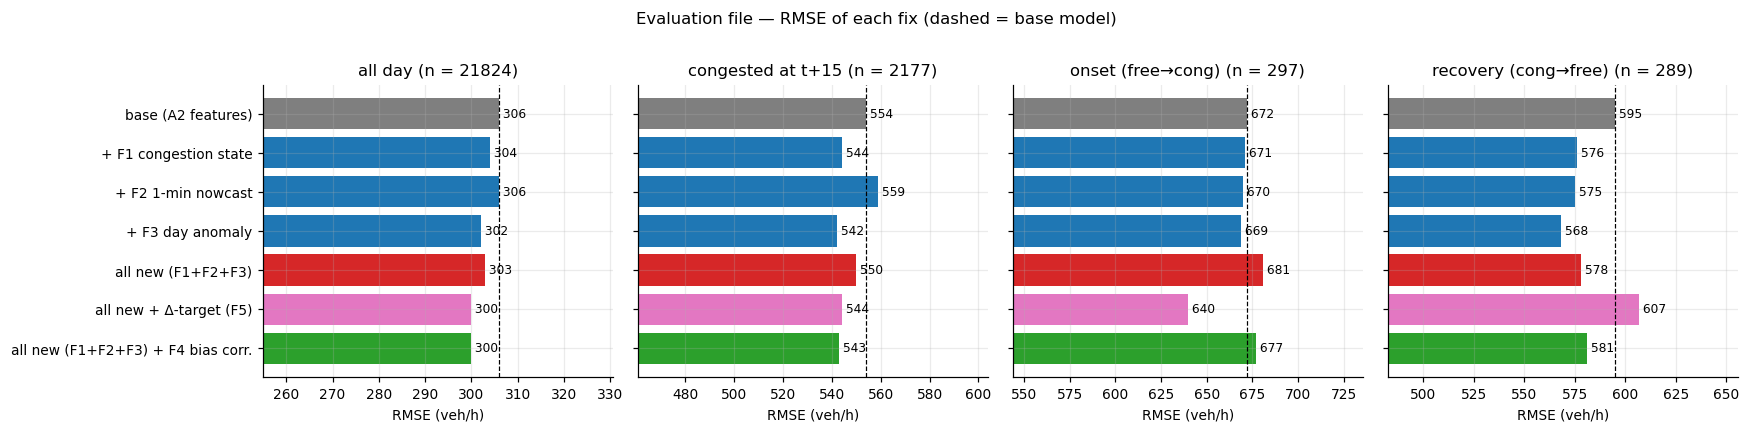

In [8]:
order = ["base (A2 features)", "+ F1 congestion state", "+ F2 1-min nowcast", "+ F3 day anomaly", "all new (F1+F2+F3)",
         "all new + Δ-target (F5)", f"{BEST_VAR} + F4 bias corr."]
subs = ["all day", "congested at t+15", "onset (free→cong)", "recovery (cong→free)"]
fig, ax = plt.subplots(1, len(subs), figsize=(16, 3.8), sharey=True)
for a, s in zip(ax, subs):
    vals = ev_tab.loc[s, order]
    a.barh(range(len(order)), vals, color=["C7"] + ["C0"] * 3 + ["C3", "C6", "C2"])
    for i, v in enumerate(vals): a.text(v, i, f" {v:.0f}", va="center", fontsize=8)
    a.axvline(ev_tab.loc[s, "base (A2 features)"], color="k", lw=.8, ls="--")
    a.set_xlim(vals.min() * .85, vals.max() * 1.08); a.set(title=f"{s} (n = {int(ev_tab.loc[s, 'n'])})", xlabel="RMSE (veh/h)")
ax[0].set_yticks(range(len(order)), order); ax[0].invert_yaxis()
fig.suptitle("Evaluation file — RMSE of each fix (dashed = base model)", y=1.02); fig.tight_layout(); save(fig, "ablation"); plt.show()

## 5. The candidate model: chosen features + masking augmentation
The variant chosen on validation is retrained with masking augmentation (as in A2), with the corridor summaries recomputed after
masking so they only use the portals that are "working". If the bias correction helped on validation, it is applied on top.

In [9]:
CAND_COLS, CAND_DELTA = COLS[BEST_VAR], DELTA[BEST_VAR]
USE_BC = grid_bc[(HL, WB)] < no_bc - 1.0          # keep the correction only if it gains > 1 veh/h on validation
def fit_candidate():
    fa = tp.corridor_features(tp.mask_augment(full, CAND_COLS, n_copies=2, seed=1))
    m = xgb.XGBRegressor(**{**base_params, "early_stopping_rounds": None, "n_estimators": int(TREES[BEST_VAR] * 1.15)}, **BEST)
    return m.fit(fa[CAND_COLS], fa[Y] - level(fa) if CAND_DELTA else fa[Y], verbose=False)
CAND = cached("candidate_aug", fit_candidate)
def cand_predict(d, y_obs=None):
    p = predict(CAND, CAND_COLS, d, CAND_DELTA)
    return tp.online_bias_correction(p, d[Y] if y_obs is None else y_obs, H, HL, WB) if USE_BC else p
NAME = f"NEW: {BEST_VAR} + aug" + (" + bias corr." if USE_BC else "")
pred[NAME] = cand_predict(ev)
cmp_tab = rmse_table({k: pred[k] for k in ["persistence", "A2 selected (xgb single + aug)", NAME]}, "evaluation")
rows = [{"subset": s, **day_test(pred[NAME], pred["A2 selected (xgb single + aug)"], "evaluation", s)}
        for s in subsets(ev)]
CMP = pd.DataFrame(rows); CMP["p (Holm)"] = holm(CMP["p"]); CMP.to_csv(RES / f"A4_new_vs_A2_{TARGET}.csv", index=False)
print("bias correction used:", USE_BC); display(cmp_tab)
CMP.round({"ΔRMSE": 1}).assign(p=lambda t: t.p.map("{:.2g}".format), **{"p (Holm)": lambda t: t["p (Holm)"].map("{:.2g}".format)})

bias correction used: True


,n,persistence,A2 selected (xgb single + aug),NEW: all new (F1+F2+F3) + aug + bias corr.
all day,21824,403.0,300.0,297.0
07:30–08:30,1040,411.0,268.0,269.0
15:00–18:00,2958,559.0,464.0,459.0
free flow at t+15,19646,370.0,259.0,256.0
congested at t+15,2177,623.0,544.0,540.0
onset (free→cong),297,749.0,663.0,667.0
recovery (cong→free),289,1045.0,552.0,557.0


,subset,ΔRMSE,95% CI,days,p,p (Holm)
0,all day,-3.2,"[-6.7, 0.0]",80,0.068,0.47
1,07:30–08:30,1.7,"[-8.6, 15.1]",80,0.79,1
2,15:00–18:00,-5.6,"[-12.8, 2.0]",80,0.15,0.89
3,free flow at t+15,-3.1,"[-7.4, 0.8]",80,0.17,0.89
4,congested at t+15,-4.6,"[-16.1, 7.0]",60,0.57,1
5,onset (free→cong),3.9,"[-15.4, 22.9]",60,0.87,1
6,recovery (cong→free),4.6,"[-27.7, 41.6]",58,0.6,1


In [10]:
# robustness: same failure scenarios as A2/A3, new model vs A2 selected model
pf = tp.portal_feature_map(CAND_COLS)
own = pf[TARGET_P]; others = sorted({c for p_, cs in pf.items() if p_ != TARGET_P for c in cs} - set(own))
vcols = sorted({c for cs in pf.values() for c in cs})
def mask_random(df, frac=0.2, seed=SEED):
    df = df.copy(); M_ = np.random.default_rng(seed).random((len(df), len(vcols))) < frac
    df[vcols] = df[vcols].mask(M_); return df
SCEN = {"no failure": lambda df: df,
        "target portal down": lambda df: df.assign(**{c: np.nan for c in own}),
        "all other portals down": lambda df: df.assign(**{c: np.nan for c in others}),
        "random 20 % missing": mask_random}
a2m = xgb.XGBRegressor(); a2m.load_model(MOD / f"xgb_single_aug_{TARGET}.json")
ok = ev[Y].notna(); y_ev = ev[Y][ok]; rob = {}
for sc, fn in SCEN.items():
    dm = tp.corridor_features(fn(ev))
    y_fb = ev[Y] * np.nan if sc == "target portal down" else None      # target sensor down -> no error feedback either
    p_new = cand_predict(dm, y_fb); p_a2 = pd.Series(a2m.predict(dm[X_BASE]), index=ev.index)
    rob[sc] = {"A2 selected": np.sqrt(((p_a2[ok] - y_ev) ** 2).mean()), NAME: np.sqrt(((p_new[ok] - y_ev) ** 2).mean())}
rob = pd.DataFrame(rob).T.round(0); rob.to_csv(RES / f"A4_robustness_{TARGET}.csv"); rob

,A2 selected,NEW: all new (F1+F2+F3) + aug + bias corr.
no failure,300.0,297.0
target portal down,307.0,303.0
all other portals down,347.0,311.0
random 20 % missing,303.0,298.0


## 6. Where did it help?

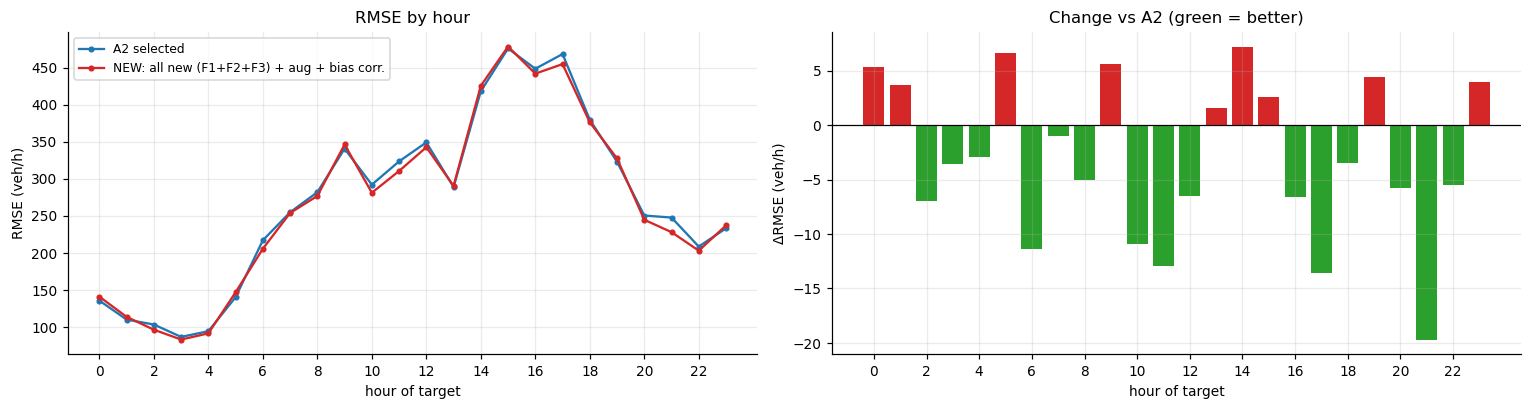

In [11]:
d = ev[ok]; hour = d["tod_target_min"] // 60
e_new, e_a2 = (pred[NAME][ok] - y_ev), (pred["A2 selected (xgb single + aug)"][ok] - y_ev)
by_h = pd.DataFrame({"A2": (e_a2 ** 2).groupby(hour).mean() ** .5, "new": (e_new ** 2).groupby(hour).mean() ** .5})
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].plot(by_h["A2"], "o-", color="C0", ms=3, label="A2 selected"); ax[0].plot(by_h["new"], "o-", color="C3", ms=3, label=NAME)
ax[0].set(xlabel="hour of target", ylabel="RMSE (veh/h)", title="RMSE by hour"); ax[0].legend(fontsize=8); ax[0].set_xticks(range(0, 24, 2))
ax[1].bar(by_h.index, by_h["new"] - by_h["A2"], color=np.where(by_h["new"] < by_h["A2"], "C2", "C3"))
ax[1].axhline(0, color="k", lw=.8); ax[1].set_xticks(range(0, 24, 2))
ax[1].set(xlabel="hour of target", ylabel="ΔRMSE (veh/h)", title="Change vs A2 (green = better)")
fig.tight_layout(); save(fig, "improvement_by_hour"); plt.show()

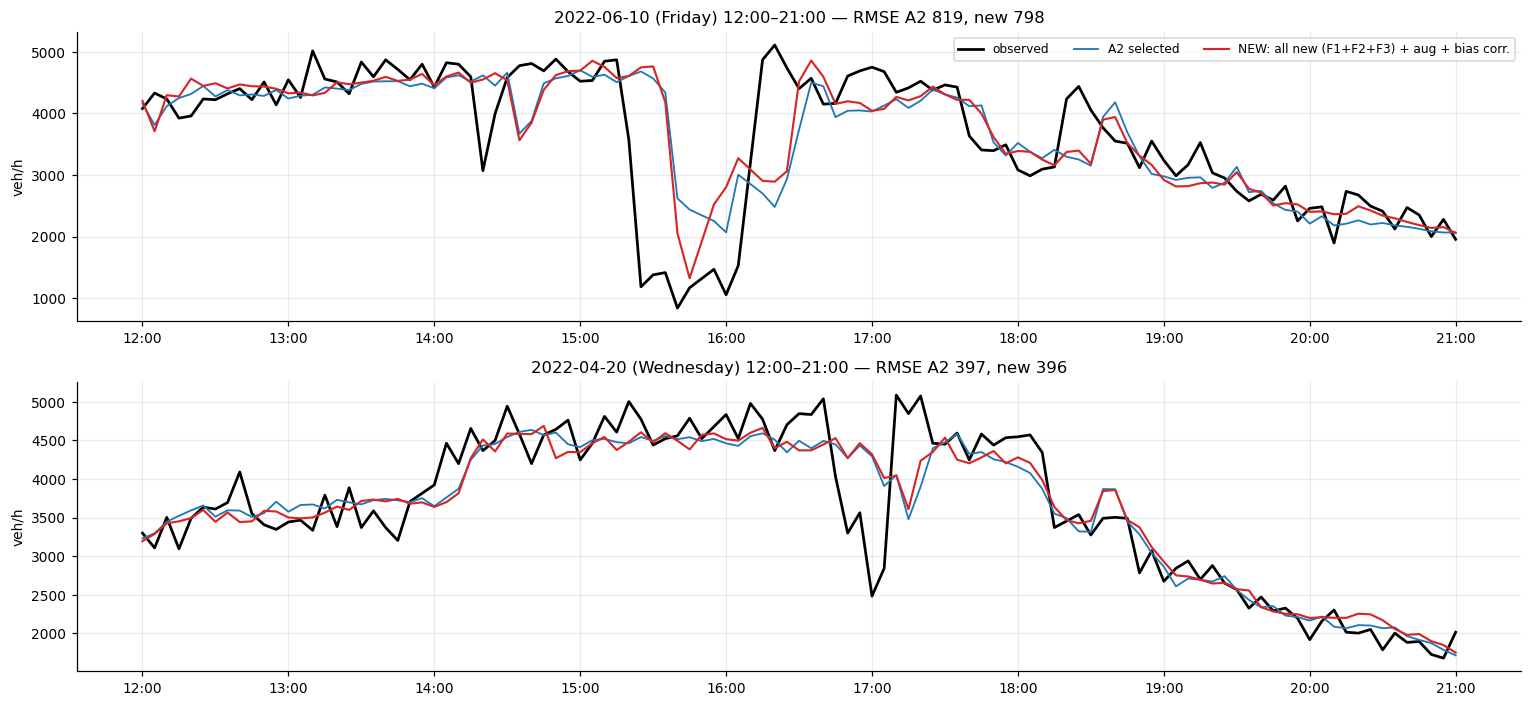

In [12]:
# the worst workday from A3 and the most congested evaluation afternoon: A2 vs new model
days = (d.index - pd.Timedelta(minutes=5)).normalize()
dr = (e_a2 ** 2).groupby(days).mean() ** .5
wd = dr[d.groupby(days)["is_offday"].first() == 0]
show_days = [wd.idxmax(), wd.sort_values().index[len(wd) // 2]]
fig, ax = plt.subplots(len(show_days), 1, figsize=(14, 6.5))
for a, day in zip(ax, show_days):
    w = (days == day) & d["tod_target_min"].between(720, 1260)
    tt = d.index[w] + pd.Timedelta(minutes=15)
    a.plot(tt, y_ev[w], "k-", lw=1.8, label="observed")
    a.plot(tt, pred["A2 selected (xgb single + aug)"][ok][w], color="C0", lw=1.2, label="A2 selected")
    a.plot(tt, pred[NAME][ok][w], color="C3", lw=1.4, label=NAME)
    a.set(ylabel="veh/h", title=f"{day.date()} ({day:%A}) 12:00–21:00 — RMSE A2 {np.sqrt((e_a2[w] ** 2).mean()):.0f}, new {np.sqrt((e_new[w] ** 2).mean()):.0f}")
    a.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))
ax[0].legend(fontsize=8, ncol=3); fig.tight_layout(); save(fig, "example_days"); plt.show()

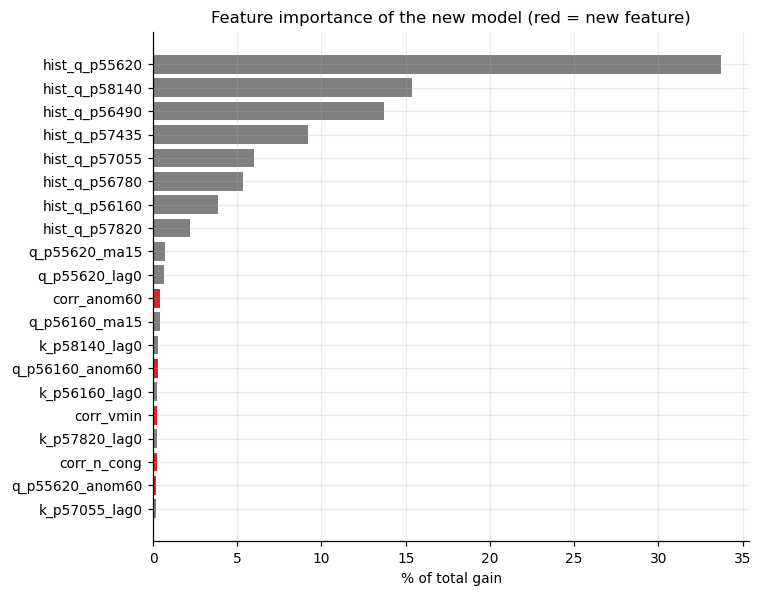

share of total gain from new features: 4%


In [13]:
g = pd.Series(CAND.get_booster().get_score(importance_type="gain")).sort_values(ascending=False)
top = (g.head(20) / g.sum() * 100)[::-1]
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top.index, top.values, color=["C3" if c in new_cols else "C7" for c in top.index])
ax.set(xlabel="% of total gain", title="Feature importance of the new model (red = new feature)")
fig.tight_layout(); save(fig, "feature_importance"); plt.show()
print(f"share of total gain from new features: {g[g.index.isin(new_cols)].sum() / g.sum():.0%}")

In [14]:
CAND.save_model(MOD / f"xgb_congfix_aug_{TARGET}.json")
joblib.dump({"cols": CAND_COLS, "delta_target": CAND_DELTA, "bias_correction": USE_BC, "halflife_steps": HL, "weight": WB,
             "variant": BEST_VAR, "xgb_params": BEST, "trees": int(TREES[BEST_VAR] * 1.15)}, MOD / f"congfix_config_{TARGET}.joblib")
print("saved:", MOD / f"xgb_congfix_aug_{TARGET}.json")

saved: ../models_allday/xgb_congfix_aug_q_p55620.json


## 7. How much of the error is predictable at all? (noise floor)
If the 5-min flow is a smooth signal plus white noise ε (random arrivals, stop-and-go jitter), then
y(t) − ½[y(t−5) + y(t+5)] removes the smooth part and has variance ≈ 1.5 σ²_ε. σ_ε is the error that *no* forecast can remove,
however good. The Poisson counting noise of a 5-min vehicle count (√(12·q) in veh/h) is shown as a lower reference.

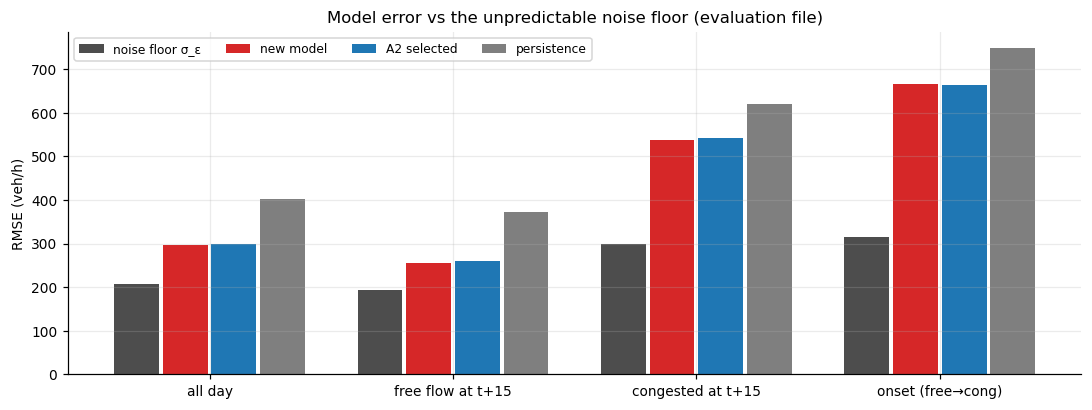

,Poisson counting noise,noise floor σ_ε,A2 selected,new model,persistence,predictable-but-missed RMSE,share of A2 MSE that is noise
all day,167.0,207.0,300.0,296.0,403.0,216.0,48%
free flow at t+15,160.0,194.0,260.0,256.0,371.0,172.0,56%
congested at t+15,222.0,299.0,542.0,538.0,621.0,452.0,30%
onset (free→cong),215.0,316.0,663.0,666.0,748.0,583.0,23%


In [15]:
g = ev[Y].reindex(pd.date_range(ev.index.min(), ev.index.max(), freq=f"{RES_MIN}min"))
hf = (g - (g.shift(1) + g.shift(-1)) / 2).reindex(ev.index)
S = subsets(ev); rows = {}
for s in ["all day", "free flow at t+15", "congested at t+15", "onset (free→cong)"]:
    m = S[s] & hf.notna()
    sig = np.sqrt((hf[m] ** 2).mean() / 1.5); pois = np.sqrt((12 * ev[Y][m].clip(lower=0)).mean())
    r_a2 = np.sqrt(((pred["A2 selected (xgb single + aug)"][m] - ev[Y][m]) ** 2).mean())
    r_new = np.sqrt(((pred[NAME][m] - ev[Y][m]) ** 2).mean()); r_p = np.sqrt(((pred["persistence"][m] - ev[Y][m]) ** 2).mean())
    rows[s] = {"Poisson counting noise": pois, "noise floor σ_ε": sig, "A2 selected": r_a2, "new model": r_new, "persistence": r_p,
               "share of A2 MSE that is noise": f"{sig ** 2 / r_a2 ** 2:.0%}",
               "predictable-but-missed RMSE": np.sqrt(max(r_a2 ** 2 - sig ** 2, 0))}
NF = pd.DataFrame(rows).T; NF.to_csv(RES / f"A4_noise_floor_{TARGET}.csv")
fig, ax = plt.subplots(figsize=(10, 3.8))
cols_ = ["noise floor σ_ε", "new model", "A2 selected", "persistence"]; x = np.arange(len(NF)); w = .2
for i, (c, col) in enumerate(zip(cols_, ["0.3", "C3", "C0", "C7"])):
    ax.bar(x + (i - 1.5) * w, NF[c].astype(float), w * .92, color=col, label=c)
ax.set_xticks(x, NF.index); ax.set(ylabel="RMSE (veh/h)", title="Model error vs the unpredictable noise floor (evaluation file)"); ax.legend(fontsize=8, ncol=4)
fig.tight_layout(); save(fig, "noise_floor"); plt.show()
NF.drop(columns="share of A2 MSE that is noise").astype(float).round(0).join(NF["share of A2 MSE that is noise"])

## Interpretation (leakage-safe rerun — check against your own numbers)

**Validation looked promising, the 2022 evaluation confirms only a small part of it.** On validation (Nov–Dec 2021) all new
features together lowered the RMSE from 284 to 276 veh/h, in congestion 512 → 498, at onsets 597 → 567. On the 2022 evaluation file
most of this disappears: every fix is within ±10 veh/h of the base model all day. Two of the 30 comparisons survive Holm, both for
the **day-anomaly features (F3)**: −4.5 veh/h all day (CI −7.1…−1.9, Holm p = 0.04) and −12 veh/h in congestion (CI −18…−6,
Holm p = 0.03). The Δ-target helps at onsets but loses at recoveries. The final candidate (all new features + augmentation +
bias correction) is 3 veh/h better than the A2 model all day (CI −6.7…0.0, not significant).

**What did improve:** robustness. With all other portals down the new model gets 311 vs 347 veh/h for A2 — the target portal's
own 1-min data and state features carry more information when the neighbours are missing.

**Why the fixes can't do much:** the noise-floor analysis shows that in free flow ~56 % of the remaining error is unpredictable
noise (σ ≈ 195 vs RMSE ≈ 260 veh/h) — the model is close to the limit. In congestion the noise floor is ≈ 300 veh/h, so about
450 veh/h of *structured* error remains, but that structure comes from stop-and-go waves generated at the bottleneck **downstream
of 55.620**. Congestion waves travel upstream, so the most downstream portal is the *first* to see them — none of the 8 portals
can give advance warning. The information needed is simply not in this dataset (downstream sensors, incident/roadwork data).

**Recommendation for the report:** keep the A2 model (XGBoost + augmentation) as the official result; present A4 as a follow-up
study: a small but real gain from the day-anomaly features (cheap to compute in real time, the most promising direction), and no
fix that closes the congestion gap — with the physical explanation. Optionally mention the new model as the better choice if
multi-sensor outages are a concern.

## 8. The final hold-out
The `final_evaluation` file was already used once, for the frozen A2 model (A3 section 3). The fixes in this notebook were designed
*after* seeing where that model failed, so a score of the new model on the same file is a **second look**, not an independent test.
Recommended reporting: keep the A2 model as the official final result, and present A4 as a follow-up study evaluated on the
evaluation file. If you still run it (`RUN_FINAL_A4 = True`), report it explicitly as a post-hoc check.

In [16]:
if RUN_FINAL_A4:
    fe = F["final_evaluation"]
    a2f = pd.read_pickle(RES / f"predictions_final_evaluation_{TARGET}.pkl")
    fin = {"persistence": level(fe), "A2 selected (xgb single + aug)": a2f["xgb single + aug"].reindex(fe.index), NAME: cand_predict(fe)}
    F["final_evaluation"] = fe; display(rmse_table(fin, "final_evaluation"))
else:
    print("RUN_FINAL_A4 is False — final hold-out not used for the new model.")

RUN_FINAL_A4 is False — final hold-out not used for the new model.
